<a href="https://colab.research.google.com/github/RORITO2312/unidad-3-transformers/blob/main/Lab03_Arquitectura_BERT_BETO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NLP + Transformers
**Lab 07 – Inspección de Arquitectura, Hidden States y Autoatención en BERT (BETO)**

---
## 1) Visualización de la Configuración de BERT 👀

In [ ]:
!pip install transformers

In [ ]:
from transformers import BertConfig, BertModel

Cargar la configuración del modelo BERT en español

In [ ]:
config = BertConfig.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")
print("Número de capas de BERT:", config.num_hidden_layers)

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

Número de capas de BERT: 12


Cargar el modelo para visualizar su arquitectura

In [ ]:
model = BertModel.from_pretrained("dccuchile/bert-base-spanish-wwm-cased", output_hidden_states=True)
print(model)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(31002, 768, padding_idx=1)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

In [ ]:
# Verificación de los hiperparámetros que se usan en el análisis
print("hidden_size (d_model):", config.hidden_size)
print("num_attention_heads:", config.num_attention_heads)
print("d_k por cabeza:", config.hidden_size // config.num_attention_heads)
print("intermediate_size (FFN):", config.intermediate_size)
print("vocab_size:", config.vocab_size)
print("max_position_embeddings:", config.max_position_embeddings)

hidden_size (d_model): 768
num_attention_heads: 12
d_k por cabeza: 64
intermediate_size (FFN): 3072
vocab_size: 31002
max_position_embeddings: 512


### 📝 Análisis – Sección 1

**1. Los tres módulos principales de `BertModel`**

| Módulo | Descripción |
|---|---|
| `embeddings` (`BertEmbeddings`) | Convierte los IDs de token en vectores de dimensión 768. Suma tres tablas: `word_embeddings` (vocabulario ≈ 31 002 × 768), `position_embeddings` (512 × 768, posición del token) y `token_type_embeddings` (2 × 768, segmento A/B). Después aplica `LayerNorm` y `Dropout`. |
| `encoder` (`BertEncoder`) | Pila de **12 bloques `BertLayer`** (índices 0–11) idénticos en estructura y con pesos independientes. Es donde se contextualiza cada token con el resto de la secuencia. |
| `pooler` (`BertPooler`) | Toma el hidden state del token `[CLS]` de la última capa y lo pasa por `Linear(768→768)` + `Tanh`. Produce un vector resumen de toda la oración (`pooler_output`), útil para clasificación. |

**2. Subcapas dentro de una `BertLayer`**

- **Atención (`attention.self`)**: tres proyecciones lineales `query`, `key` y `value`, cada una `Linear(768→768)`. Se dividen en 12 cabezas de 64 dimensiones. Con ellas se calcula `softmax(QKᵀ/√d_k)·V`.
- **`attention.output` (`BertSelfOutput`)**: `dense` (`Linear 768→768`, mezcla las cabezas concatenadas), `Dropout` y **`LayerNorm`**. Aquí ocurre la **conexión residual** (`LayerNorm(dense(contexto) + entrada)`).
- **`intermediate` (`BertIntermediate`)**: `Linear(768→3072)` + activación **GELU** (primera mitad de la red Feed-Forward).
- **`output` (`BertOutput`)**: `Linear(3072→768)`, `Dropout` y **segunda `LayerNorm`** con **segunda conexión residual** (`LayerNorm(FFN(x) + x)`).

Por tanto, `query/key/value` implementan la atención; `attention.output.LayerNorm` y `output.LayerNorm` implementan la normalización con residuales (esquema *Post-LN*).

**3. Dimensión oculta**

`hidden_size = d_model = 768`. Las proyecciones Q, K, V y las capas de salida son `Linear(768, 768)`; la FFN expande a 3072 (4·d_model) y vuelve a 768. Con 12 cabezas, cada una trabaja con `d_k = 768/12 = 64`.

## 2) Visualización de las Capas y Hidden States 🔍

In [ ]:
from transformers import BertTokenizer
import torch

Cargar tokenizer y modelo BERT en español

In [ ]:
tokenizer = BertTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")
model = BertModel.from_pretrained("dccuchile/bert-base-spanish-wwm-cased", output_hidden_states=True)

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Texto de ejemplo

In [ ]:
text = "El producto de Samsung Galaxy S21 llegó el 12 de marzo y superó mis expectativas."
inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128)
outputs = model(**inputs)

In [ ]:
print(outputs)

BaseModelOutputWithPoolingAndCrossAttentions(last_hidden_state=tensor([[[-0.3688, -0.2218, -0.6865,  ..., -0.4430,  0.2883,  0.1794],
         [-0.2616, -0.0662, -0.6243,  ..., -0.5904,  0.6507,  0.2768],
         [-0.2415, -0.2261, -0.6785,  ..., -0.1096,  0.0910,  0.5395],
         ...,
         [-1.4393, -0.1986, -0.5770,  ..., -0.5261,  0.0716,  1.0376],
         [-0.7026,  0.3509, -0.4953,  ..., -0.3322,  0.3734,  0.1284],
         [-1.2273, -0.4597, -1.0296,  ..., -0.6864,  0.9237, -0.5841]]],
       grad_fn=<NativeLayerNormBackward0>), pooler_output=tensor([[ 9.9008e-02,  3.5788e-01, -4.1323e-01, -4.8817e-01, -4.2094e-01,
         -2.1868e-01,  1.3337e-01, -4.1272e-01, -3.4041e-01,  9.4003e-02,
          4.7298e-01,  5.3786e-01,  1.7437e-01, -6.6452e-02, -7.3087e-01,
         -5.0685e-01, -5.9694e-01,  1.8136e-01, -3.5738e-01, -7.6596e-03,
          2.8517e-01, -2.0389e-01,  2.5431e-01,  6.6622e-02,  2.0691e-01,
          7.4671e-01, -3.1673e-01,  3.6801e-01, -2.2740e-01, -3.152

In [ ]:
# Inspección del diccionario inputs
print(inputs)
print()
print("Tokens:", tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))
print("input_ids shape:", inputs["input_ids"].shape)

{'input_ids': tensor([[    4,  1162,  4196,  1008,  4262,  8643, 16685, 21291, 24010,  1057,
          8926,  4444,  1040,  1797,  1008,  3008,  1042, 27994,  1354, 12956,
          1009,     5]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

Tokens: ['[CLS]', 'El', 'producto', 'de', 'Sam', '##su', '##ng', 'Gala', '##xy', 'S', '##21', 'llegó', 'el', '12', 'de', 'marzo', 'y', 'superó', 'mis', 'expectativas', '.', '[SEP]']
input_ids shape: torch.Size([1, 22])


Extraer los hidden states

In [ ]:
hidden_states = outputs.hidden_states
print("Número de capas (incluyendo la capa de embedding):", len(hidden_states))

Número de capas (incluyendo la capa de embedding): 13


Por ejemplo, si BERT base tiene 12 capas, se imprimirá 13 (1 de embedding + 12 codificadores)

In [ ]:
# Línea agregada: forma del tensor de la posición 0
print("hidden_states[0].shape:", hidden_states[0].shape)
print("hidden_states[-1].shape:", hidden_states[-1].shape)

hidden_states[0].shape: torch.Size([1, 22, 768])
hidden_states[-1].shape: torch.Size([1, 22, 768])


### 📝 Análisis – Sección 2

**1. Diccionario `inputs`**

- **`input_ids`**: tensor con el ID entero de cada token en el vocabulario de BETO. El tokenizador (WordPiece) añade `[CLS]` al inicio y `[SEP]` al final, y las palabras poco frecuentes (p. ej. *Samsung*, *Galaxy*, *S21*) pueden dividirse en subpalabras (`##...`), por eso hay más IDs que palabras.
- **`token_type_ids`**: indica a qué segmento pertenece cada token (0 = oración A, 1 = oración B). Se usa en tareas con pares de oraciones (NSP, QA, inferencia). Aquí hay una sola oración, así que **todos son 0**; estos IDs seleccionan una fila de `token_type_embeddings`.
- **`attention_mask`**: marca con 1 los tokens reales y con 0 el relleno (*padding*), para que la atención ignore el padding. Está compuesto solo por **1** porque procesamos **una única oración sin padding** (no hay tokens de relleno que enmascarar).

**2. ¿Por qué `len(hidden_states) = 13` con 12 capas?**

`hidden_states` es una tupla con la salida de **cada etapa**: la posición **0** es la **salida de la capa de embeddings** (suma de embeddings de palabra + posición + segmento, con LayerNorm), es decir, la entrada al primer encoder, antes de pasar por cualquier bloque de atención. Las posiciones 1–12 son las salidas de los 12 `BertLayer`. Total: 1 + 12 = **13**. `hidden_states[-1]` coincide con `last_hidden_state`.

**3. `hidden_states[0].shape` → `[1, 22, 768]`**

- **`batch_size = 1`**: número de oraciones procesadas a la vez (una sola).
- **`sequence_length = 22`**: número de tokens tras la tokenización, incluyendo `[CLS]` y `[SEP]` (ver la lista de tokens impresa arriba). Es mayor que el número de palabras por las subpalabras.
- **`hidden_size = 768`**: dimensión del vector que representa cada token (`d_model`).

La forma se mantiene `[1, 22, 768]` en las 13 posiciones: las capas del encoder transforman el contenido pero no cambian la forma.

**Resultado obtenido en mi ejecución:** `hidden_states[0].shape = torch.Size([1, 22, 768])`. La oración tiene 15 palabras más el punto final, pero se tokenizó en **22 tokens**: `[CLS]` + 20 tokens de texto + `[SEP]`. Las palabras *Samsung*, *Galaxy* y *S21* se dividieron en subpalabras (`Sam ##su ##ng`, `Gala ##xy`, `S ##21`) porque no existen completas en el vocabulario de BETO. Por eso `input_ids`, `token_type_ids` y `attention_mask` tienen longitud 22, y `attention_mask` es todo 1 porque no hay padding.


## 3) Diagrama Conceptual y Pseudocódigo 🙌

Pseudocódigo del mecanismo de Self-Attention

### 📝 Pseudocódigo paso a paso de Self-Attention

$$\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

```
ENTRADA:  X  de forma [L, d_model]      # hidden states de la capa anterior (d_model = 768)
          W_Q, W_K, W_V de forma [d_model, d_model]
          h = 12 cabezas, d_k = d_model / h = 64
          mask (1 = token real, 0 = padding)

1. Proyección lineal:
      Q = X · W_Q + b_Q          # [L, 768]  "qué busca cada token"
      K = X · W_K + b_K          # [L, 768]  "qué ofrece cada token"
      V = X · W_V + b_V          # [L, 768]  "qué información aporta"

2. Dividir en h cabezas:
      Q, K, V  →  [h, L, d_k]

3. PARA CADA cabeza i = 1..h:
      a) scores_i  = Q_i · K_iᵀ           # [L, L] similitud entre todos los pares de tokens
      b) scores_i  = scores_i / sqrt(d_k) # escalado: evita softmax saturado
      c) scores_i  = scores_i + (-inf donde mask == 0)   # ignora el padding
      d) A_i       = softmax(scores_i, por filas)        # pesos de atención, cada fila suma 1
      e) head_i    = A_i · V_i            # [L, d_k] suma ponderada de los valores

4. Concatenar cabezas:   H = concat(head_1..head_h)   # [L, 768]
5. Proyección de salida:  O = H · W_O + b_O            # BertSelfOutput.dense
6. Residual + norma:      salida = LayerNorm(O + X)    # BertSelfOutput.LayerNorm
```

In [ ]:
import math

# Self-Attention con los pesos REALES de la capa 0 de BETO
layer0 = model.encoder.layer[0].attention.self
X = hidden_states[0]                      # [1, L, 768] (salida de embeddings)
B, L, D = X.shape
h = config.num_attention_heads            # 12
d_k = D // h                              # 64

def split_heads(t):                       # [B, L, 768] -> [B, h, L, d_k]
    return t.view(B, L, h, d_k).transpose(1, 2)

with torch.no_grad():
    Q = split_heads(layer0.query(X))      # 1. proyecciones lineales + 2. cabezas
    K = split_heads(layer0.key(X))
    V = split_heads(layer0.value(X))

    scores = Q @ K.transpose(-2, -1)      # 3a. QK^T       -> [B, h, L, L]
    scores = scores / math.sqrt(d_k)      # 3b. escalado
    mask = inputs["attention_mask"][:, None, None, :]
    scores = scores.masked_fill(mask == 0, float("-inf"))   # 3c. máscara
    A = torch.softmax(scores, dim=-1)     # 3d. pesos de atención
    context = A @ V                       # 3e. suma ponderada -> [B, h, L, d_k]
    context = context.transpose(1, 2).reshape(B, L, D)      # 4. concatenar cabezas

print("Q, K, V:", Q.shape)
print("Atención A:", A.shape, "-> cada fila suma 1:", torch.allclose(A.sum(-1), torch.ones_like(A.sum(-1))))
print("Contexto:", context.shape)

Q, K, V: torch.Size([1, 12, 22, 64])
Atención A: torch.Size([1, 12, 22, 22]) -> cada fila suma 1: True
Contexto: torch.Size([1, 22, 768])


### 🖼️ Diagrama conceptual del flujo de Self-Attention

El siguiente diagrama muestra cómo viaja el tensor `X = hidden_states[0]` (`[1, 22, 768]`) por `BertSelfAttention` y `BertSelfOutput` en la capa 0 de BETO, con las formas reales obtenidas en esta ejecución.

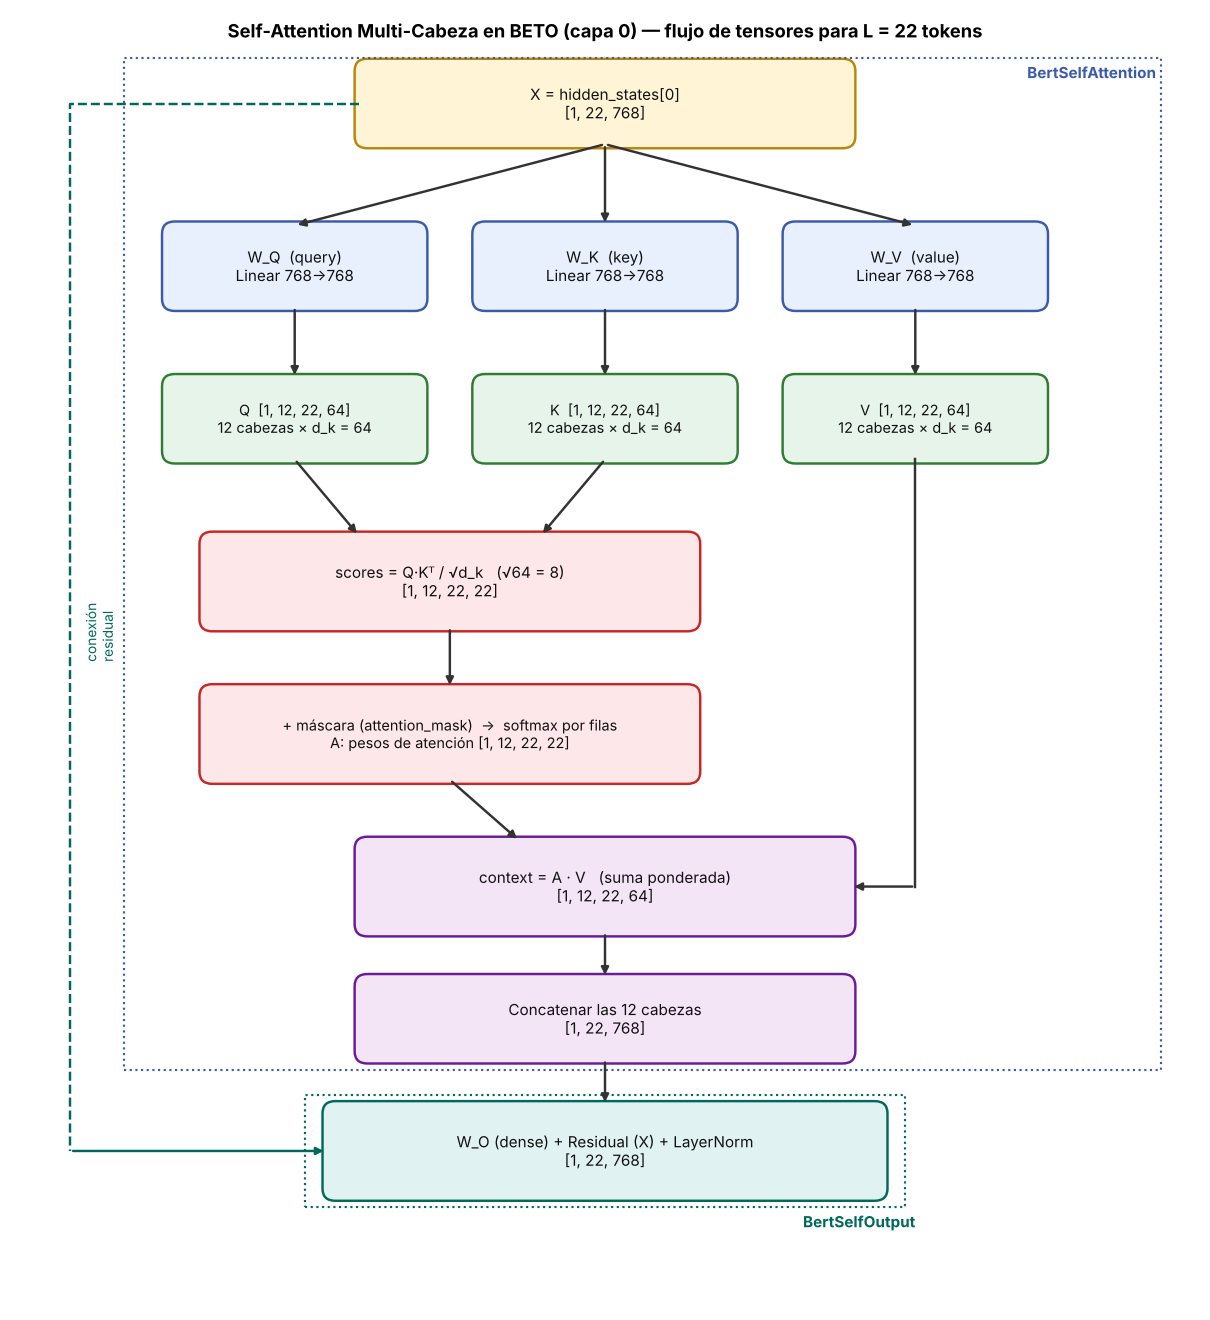

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

fig, ax = plt.subplots(figsize=(11, 12), facecolor="white")
ax.set_xlim(0, 11); ax.set_ylim(0, 12.6); ax.axis("off")

def box(x, y, w, h, text, fc="#E8F0FE", ec="#3B5BA9", fs=10):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color="#111111")

def arrow(x1, y1, x2, y2, color="#333333"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

# Entrada
box(5.5, 11.8, 4.6, 0.8, "X = hidden_states[0]\n[1, 22, 768]", fc="#FFF4D6", ec="#B8860B")
# Proyecciones
xs = [2.6, 5.5, 8.4]
for x, n in zip(xs, ["W_Q  (query)", "W_K  (key)", "W_V  (value)"]):
    box(x, 10.2, 2.4, 0.8, f"{n}\nLinear 768→768", fc="#E8F0FE")
    arrow(5.5, 11.4, x, 10.6)
# Q K V
for x, n in zip(xs, ["Q", "K", "V"]):
    box(x, 8.7, 2.4, 0.8, f"{n}  [1, 12, 22, 64]\n12 cabezas × d_k = 64", fc="#E6F4EA", ec="#2E7D32", fs=9.5)
    arrow(x, 9.8, x, 9.1)
# Scores
box(4.05, 7.1, 4.6, 0.9, "scores = Q·Kᵀ / √d_k   (√64 = 8)\n[1, 12, 22, 22]", fc="#FDE7E9", ec="#C62828")
arrow(2.6, 8.3, 3.2, 7.55); arrow(5.5, 8.3, 4.9, 7.55)
# Mascara + softmax
box(4.05, 5.6, 4.6, 0.9, "+ máscara (attention_mask)  →  softmax por filas\nA: pesos de atención [1, 12, 22, 22]", fc="#FDE7E9", ec="#C62828", fs=9.5)
arrow(4.05, 6.65, 4.05, 6.05)
# A·V
box(5.5, 4.1, 4.6, 0.9, "context = A · V   (suma ponderada)\n[1, 12, 22, 64]", fc="#F3E5F5", ec="#6A1B9A")
arrow(4.05, 5.15, 4.7, 4.55)
ax.plot([8.4, 8.4], [8.3, 4.1], color="#333333", lw=1.6)
arrow(8.4, 4.1, 7.8, 4.1)
# Concat
box(5.5, 2.8, 4.6, 0.8, "Concatenar las 12 cabezas\n[1, 22, 768]", fc="#F3E5F5", ec="#6A1B9A")
arrow(5.5, 3.65, 5.5, 3.2)
# Salida attention
box(5.5, 1.5, 5.2, 0.9, "W_O (dense) + Residual (X) + LayerNorm\n[1, 22, 768]", fc="#E0F2F1", ec="#00695C")
arrow(5.5, 2.4, 5.5, 1.95)
# Residual
ax.plot([3.2, 0.5, 0.5], [11.8, 11.8, 1.5], color="#00695C", lw=1.6, ls="--")
arrow(0.5, 1.5, 2.9, 1.5, color="#00695C")
ax.text(0.62, 6.6, "conexión\nresidual", rotation=90, va="center", fontsize=9, color="#00695C")
# Marcos de modulos
ax.add_patch(Rectangle((1.0, 2.3), 9.7, 9.95, fill=False, ec="#3B5BA9", ls=":", lw=1.4, clip_on=False))
ax.text(10.65, 12.05, "BertSelfAttention", ha="right", fontsize=10, color="#3B5BA9", fontweight="bold")
ax.add_patch(Rectangle((2.7, 0.95), 5.6, 1.1, fill=False, ec="#00695C", ls=":", lw=1.4))
ax.text(8.4, 0.75, "BertSelfOutput", ha="right", fontsize=10, color="#00695C", fontweight="bold")
ax.text(5.5, 12.45, "Self-Attention Multi-Cabeza en BETO (capa 0) — flujo de tensores para L = 22 tokens",
        ha="center", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### 📝 Análisis – Sección 3

**1. Pseudocódigo:** ver la celda del pseudocódigo (pasos 1–6), su implementación ejecutable y el diagrama conceptual (con las formas reales `[1, 12, 22, 64]` y `[1, 12, 22, 22]`), que usa los pesos reales `query`, `key`, `value` de la capa 0 de BETO. Cada token se proyecta a Q, K y V; `QKᵀ` mide cuánto "atiende" cada token a todos los demás; dividir por √d_k (=8) mantiene los valores en un rango estable para el softmax; el softmax convierte los puntajes en pesos que suman 1; y multiplicar por V produce, para cada token, una **suma ponderada** de la información de toda la secuencia (de ahí la bidireccionalidad de BERT). Las 12 cabezas se concatenan y pasan por la proyección de salida, el residual y `LayerNorm`.

**2. ¿Por qué va al cierre del laboratorio y cómo se relaciona con `BertSelfAttention`?**

Primero se necesita observar la estructura real del modelo (Sección 1) y cómo fluyen los tensores `[batch, seq_len, 768]` por las capas (Sección 2); solo entonces la formalización matemática tiene sentido, porque se puede **mapear cada operación a un módulo observado**: las proyecciones `W_Q, W_K, W_V` son los `Linear` `query`, `key` y `value` de `BertSelfAttention` (visibles en el `print(model)` de la Sección 1); el cálculo de scores, softmax y suma con V ocurre dentro del `forward` de ese módulo (no tiene parámetros, por eso no aparece en el print); y la proyección `W_O`, el residual y `LayerNorm` corresponden a `BertSelfOutput`. Así el cierre integra lo visto: la arquitectura (qué capas existen), los hidden states (qué datos entran y salen) y el algoritmo (qué computa cada capa).
